In [96]:
import pandas as pd
import numpy as np
import librosa.display
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor, as_completed
import multiprocessing
from tqdm import tqdm
import shutil
from sklearn.model_selection import train_test_split
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay

In [6]:
metadata = pd.read_csv('metadata.csv')

In [12]:
dataset = pd.read_csv('final_dataset.csv')
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 821 entries, 0 to 820
Data columns (total 52 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   zero_crossing_rate   821 non-null    float64
 1   energy               821 non-null    float64
 2   spectral_centroid    821 non-null    float64
 3   spectral_bandwidth   821 non-null    float64
 4   log_mel_1            821 non-null    float64
 5   log_mel_2            821 non-null    float64
 6   log_mel_3            821 non-null    float64
 7   log_mel_4            821 non-null    float64
 8   log_mel_5            821 non-null    float64
 9   log_mel_6            821 non-null    float64
 10  log_mel_7            821 non-null    float64
 11  log_mel_8            821 non-null    float64
 12  log_mel_9            821 non-null    float64
 13  log_mel_10           821 non-null    float64
 14  log_mel_11           821 non-null    float64
 15  log_mel_12           821 non-null    flo

# Gender Classification

In [13]:
dataset['gender'].value_counts()

gender
male      631
female    190
Name: count, dtype: int64

In [16]:
dataset['gender'] = dataset['gender'].apply(lambda x: 1 if x == 'male' else 0)

In [17]:
gender_dataset = dataset.drop(columns=['has_intro', 'student_id', 'question_number', 'file_name'], inplace=False)

In [19]:
gender_dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 821 entries, 0 to 820
Data columns (total 48 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   zero_crossing_rate   821 non-null    float64
 1   energy               821 non-null    float64
 2   spectral_centroid    821 non-null    float64
 3   spectral_bandwidth   821 non-null    float64
 4   log_mel_1            821 non-null    float64
 5   log_mel_2            821 non-null    float64
 6   log_mel_3            821 non-null    float64
 7   log_mel_4            821 non-null    float64
 8   log_mel_5            821 non-null    float64
 9   log_mel_6            821 non-null    float64
 10  log_mel_7            821 non-null    float64
 11  log_mel_8            821 non-null    float64
 12  log_mel_9            821 non-null    float64
 13  log_mel_10           821 non-null    float64
 14  log_mel_11           821 non-null    float64
 15  log_mel_12           821 non-null    flo

In [21]:
# Select 190 samples each from males and females
male_samples = gender_dataset[gender_dataset['gender'] == 1].sample(n=190, random_state=42)
female_samples = gender_dataset[gender_dataset['gender'] == 0].sample(n=190, random_state=42)

balanced_dataset = pd.concat([male_samples, female_samples])

train_set, test_set = train_test_split(balanced_dataset, test_size=0.25, random_state=42, stratify=balanced_dataset['gender'])

# Display the shapes of the resulting datasets
print(f"Training set shape: {train_set.shape}")
print(f"Testing set shape: {test_set.shape}")

Training set shape: (285, 48)
Testing set shape: (95, 48)


In [38]:
def get_corr(data):
    num_cols = data.select_dtypes(include=['int64', 'float64']).columns   
    corr_matrix = data[num_cols].corr()
    upper_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    high_corr_features = [(column, upper_triangle[column].idxmax(), upper_triangle[column].max()) for column in upper_triangle.columns if any(upper_triangle[column] > 0.9)]
    for feature1, feature2, corr_value in high_corr_features:
        print(f"{feature1} and {feature2} have a correlation of {corr_value}")
    return corr_matrix

spectral_centroid and zero_crossing_rate have a correlation of 0.9903635146873123
log_mel_5 and log_mel_4 have a correlation of 0.9460780907280261
log_mel_6 and log_mel_5 have a correlation of 0.9659725629604006
log_mel_7 and log_mel_6 have a correlation of 0.960022540388093
log_mel_8 and log_mel_7 have a correlation of 0.9538645703183916
log_mel_9 and log_mel_8 have a correlation of 0.9228917991222666
log_mel_10 and log_mel_9 have a correlation of 0.910924004730554
log_mel_12 and log_mel_11 have a correlation of 0.901269345264183
log_mel_17 and log_mel_16 have a correlation of 0.9337996433657169
log_mel_18 and log_mel_17 have a correlation of 0.9393516028918286
log_mel_19 and log_mel_18 have a correlation of 0.933225958834208
log_mel_20 and log_mel_19 have a correlation of 0.9417058169778803
log_mel_21 and log_mel_20 have a correlation of 0.9734443556833696
log_mel_22 and log_mel_21 have a correlation of 0.9671741526035247
mfcc_2 and log_mel_3 have a correlation of 0.900788847611454


<Axes: >

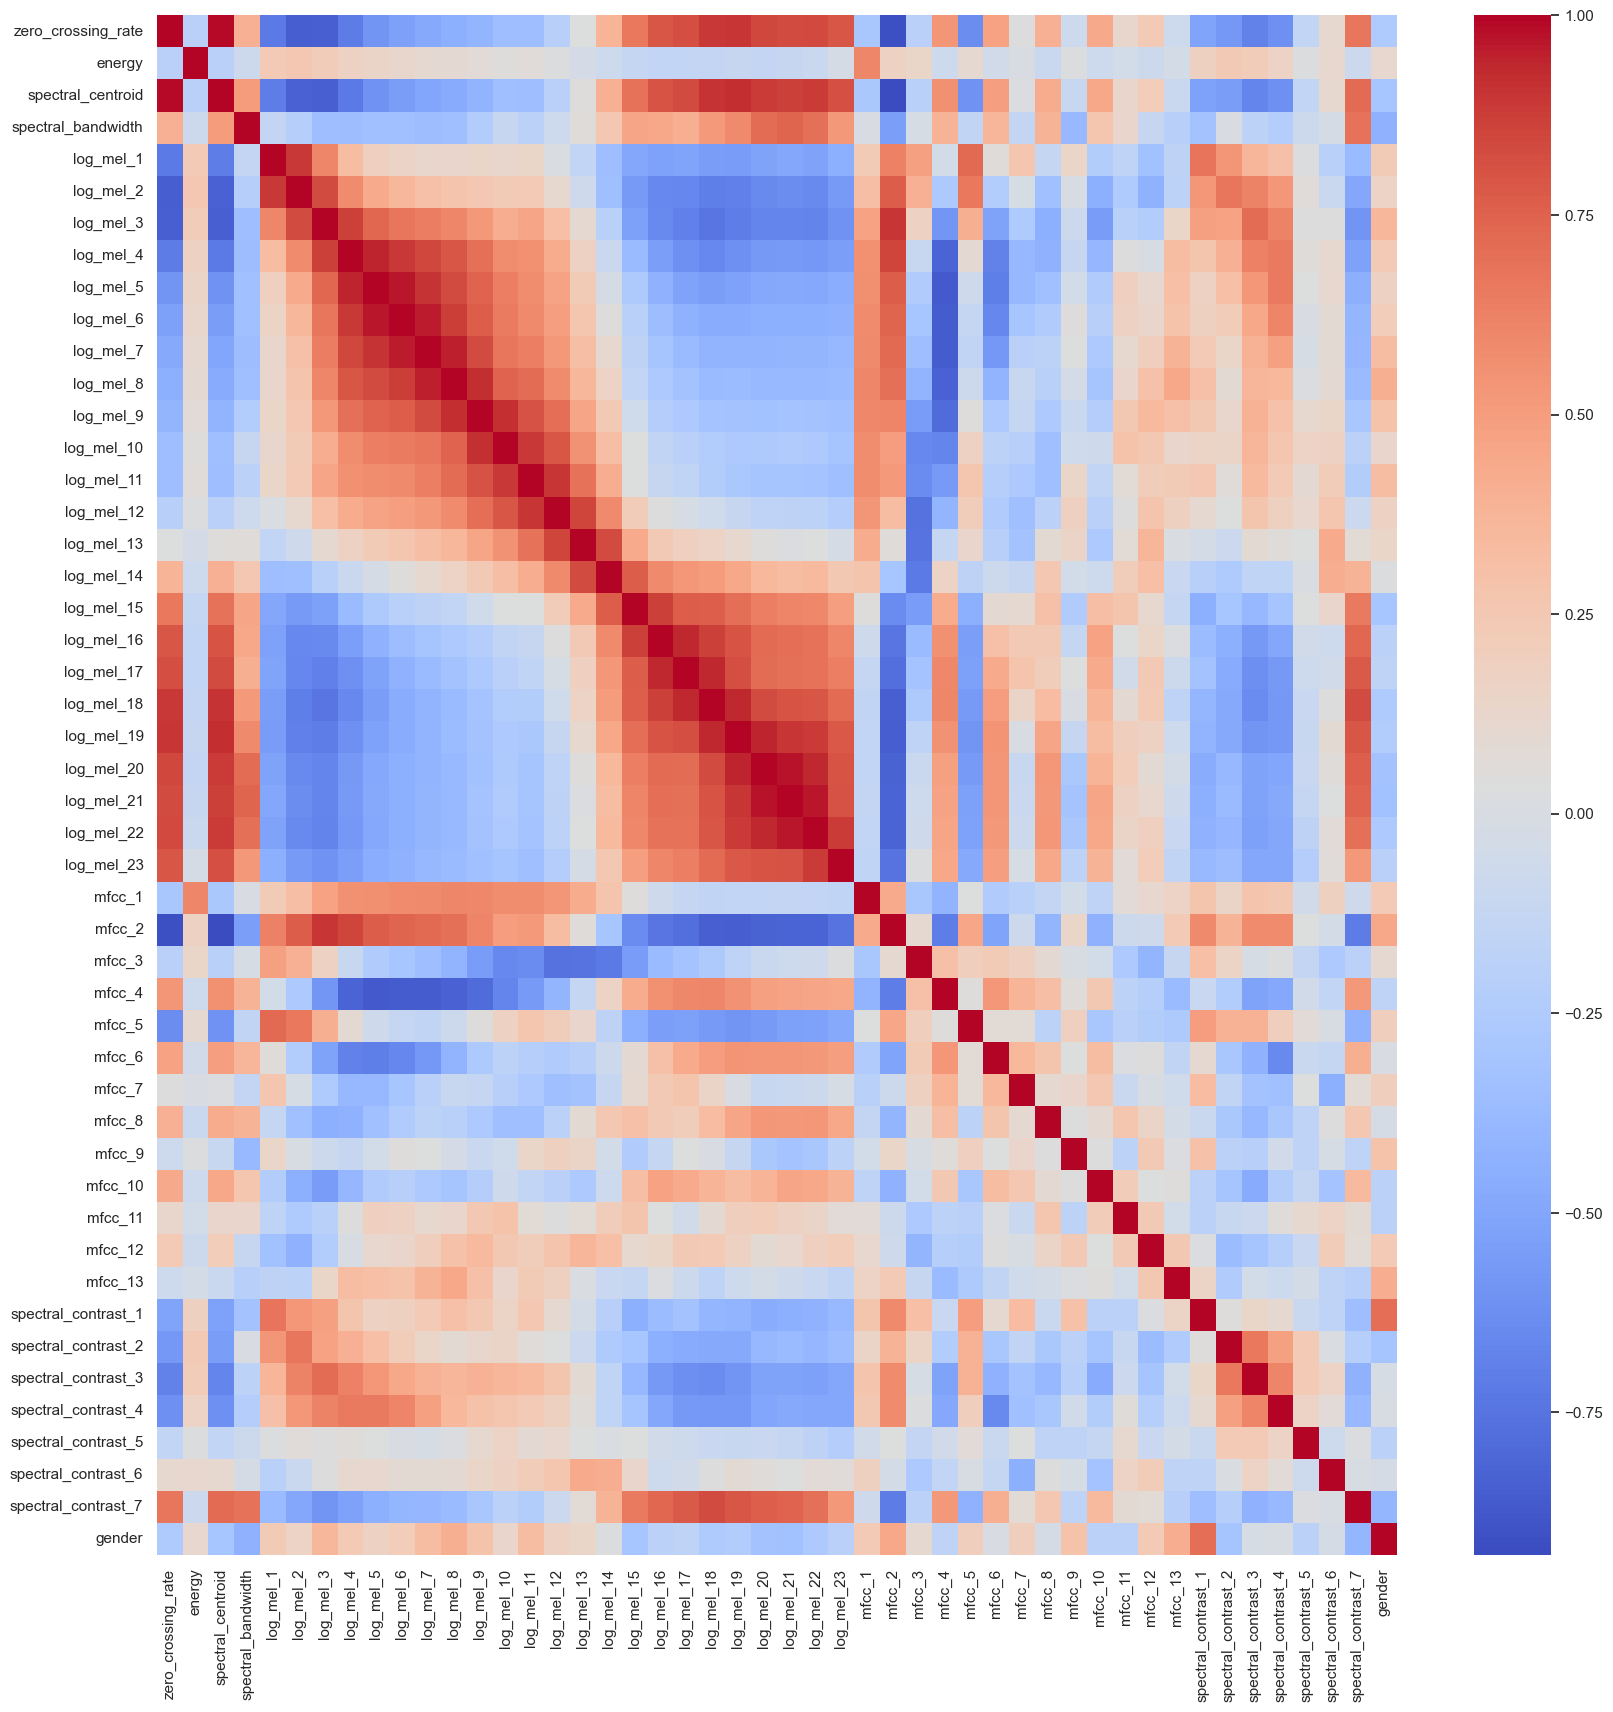

In [32]:
corr_matrix = get_corr(balanced_dataset)
sns.set(rc={'figure.figsize':(20,20)})
sns.heatmap(corr_matrix, cmap="coolwarm", annot=False)


In [59]:
df = balanced_dataset.copy()

log_mel_features = [col for col in df.columns if "log_mel" in col]
log_mel_data = df[log_mel_features]

scaler = StandardScaler()
log_mel_scaled = scaler.fit_transform(log_mel_data)

pca = PCA(n_components=0.95)
log_mel_pca = pca.fit_transform(log_mel_scaled)

pca_columns = [f"log_mel_pca_{i}" for i in range(log_mel_pca.shape[1])]
df_pca = pd.DataFrame(log_mel_pca, columns=pca_columns)

df = df.drop(columns=log_mel_features)
df.reset_index(drop=True, inplace=True)
df_pca.reset_index(drop=True, inplace=True)
df = pd.concat([df, df_pca], axis=1)

print(f"Original log-mel features: {len(log_mel_features)}, Reduced to: {len(pca_columns)}")


Original log-mel features: 23, Reduced to: 8


In [62]:
corr_matrix = get_corr(df)

spectral_centroid and zero_crossing_rate have a correlation of 0.9903635146873123
log_mel_pca_0 and mfcc_2 have a correlation of 0.9786177248941503


In [63]:
print(df['spectral_centroid'].corr(df['gender']))
print(df['zero_crossing_rate'].corr(df['gender']))

print(df['log_mel_pca_0'].corr(df['gender']))
print(df['mfcc_2'].corr(df['gender']))

-0.29786641424890303
-0.25609009781171366
0.33240019625432754
0.44319399123839637


In [64]:
df.drop(columns=['zero_crossing_rate', 'log_mel_pca_0'], inplace=True)

In [65]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 380 entries, 0 to 379
Data columns (total 31 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   energy               380 non-null    float64
 1   spectral_centroid    380 non-null    float64
 2   spectral_bandwidth   380 non-null    float64
 3   mfcc_1               380 non-null    float64
 4   mfcc_2               380 non-null    float64
 5   mfcc_3               380 non-null    float64
 6   mfcc_4               380 non-null    float64
 7   mfcc_5               380 non-null    float64
 8   mfcc_6               380 non-null    float64
 9   mfcc_7               380 non-null    float64
 10  mfcc_8               380 non-null    float64
 11  mfcc_9               380 non-null    float64
 12  mfcc_10              380 non-null    float64
 13  mfcc_11              380 non-null    float64
 14  mfcc_12              380 non-null    float64
 15  mfcc_13              380 non-null    flo

In [66]:
train_set, test_set = train_test_split(df, test_size=0.25, random_state=42, stratify=df['gender'])
print(f"Training set shape: {train_set.shape}")
print(f"Testing set shape: {test_set.shape}")

Training set shape: (285, 31)
Testing set shape: (95, 31)


In [67]:
train_set['gender'].value_counts()

gender
1    143
0    142
Name: count, dtype: int64

In [68]:
test_set['gender'].value_counts()   

gender
0    48
1    47
Name: count, dtype: int64

# Normalization

In [71]:
X = df.drop(columns=["gender"])
y = df["gender"] 

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=95/380, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Training Models

In [113]:
models = {
    "SVM": SVC(kernel="rbf", probability=True, random_state=42),
    "Logistic Regression": LogisticRegression(random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5)
}

predictions = {
    "MLP": [],
    "SVM": [],
    "Logistic Regression": [],
    "KNN": [],
}

probabilities = {
    "MLP": [],
    "SVM": [],
    "Logistic Regression": [],
    "KNN": [],
}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    predictions[name] = y_pred
    probabilities[name] = y_prob
    accuracy = accuracy_score(y_test, y_pred)
    print(f" {name} Accuracy: {accuracy:.4f}")
    # print(classification_report(y_test, y_pred))


 SVM Accuracy: 0.9684
 Logistic Regression Accuracy: 0.9474
 KNN Accuracy: 0.9158


In [114]:
MLP = MLPClassifier(
    hidden_layer_sizes=(128, 64, 32),  # Deeper network with more neurons
    activation="relu",                 # Better activation for deep learning
    solver="adam",                      # Adaptive learning rate optimization
    alpha=0.02,                       # L2 regularization (prevents overfitting)
    batch_size=16,                      # Smaller batch size for better convergence
    learning_rate="adaptive",           # Adjusts learning rate dynamically
    max_iter=1000,                      # More epochs for better training
    random_state=42
)

MLP.fit(X_train, y_train)

y_pred_optimized = MLP.predict(X_test)
y_proba = MLP.predict_proba(X_test)[:, 1]
predictions["MLP"] = y_pred_optimized
probabilities["MLP"] = y_proba
accuracy_optimized = accuracy_score(y_test, y_pred_optimized)


print(f"MLP Accuracy: {accuracy_optimized:.4f}")
print(classification_report(y_test, y_pred_optimized))


MLP Accuracy: 0.9684
              precision    recall  f1-score   support

           0       0.94      1.00      0.97        48
           1       1.00      0.94      0.97        47

    accuracy                           0.97        95
   macro avg       0.97      0.97      0.97        95
weighted avg       0.97      0.97      0.97        95



In [115]:
def ROC_curve(y_true, y_prob, model_name):
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
    plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  # Diagonal line
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(model_name +' ROC Curve')
    plt.legend(loc="lower right")
    plt.grid()
    plt.show()

In [116]:
def confusion_matrix_plot(y_true, y_pred, model_name):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Male", "Female"], yticklabels=["Male", "Female"])
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(model_name+ " Confusion Matrix")
    plt.show()

# MLP model

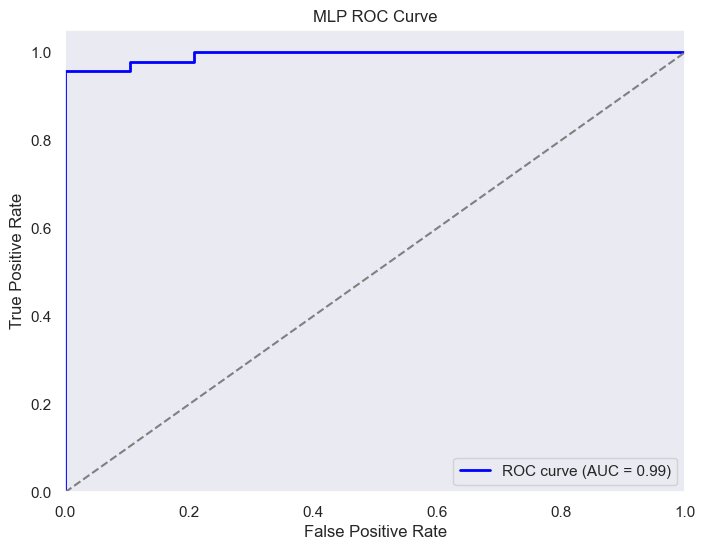

In [117]:
y_pred = predictions["MLP"]
y_proba = probabilities["MLP"]

ROC_curve(y_test, y_proba, "MLP")

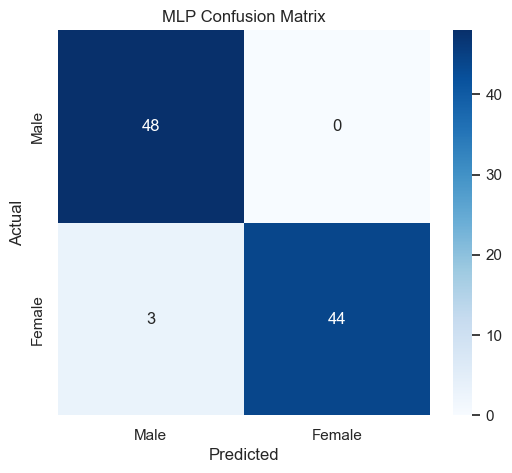

In [118]:
confusion_matrix_plot(y_test, y_pred, "MLP")

# SVM

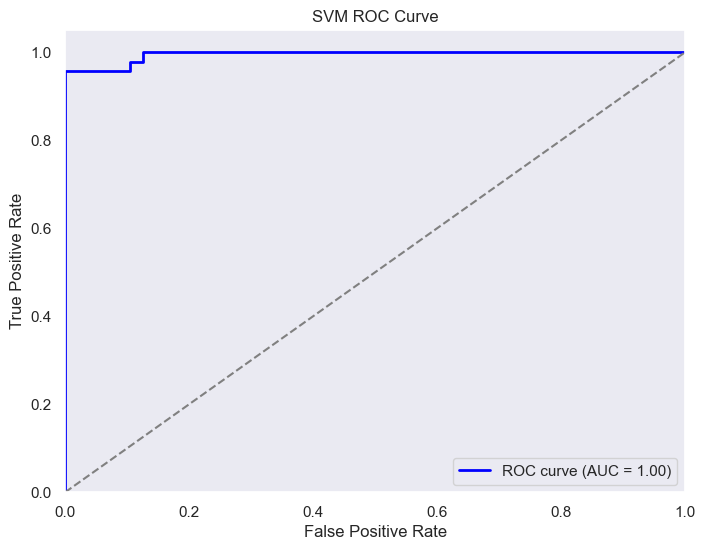

In [119]:
y_pred = predictions["SVM"]
y_proba = probabilities["SVM"]

ROC_curve(y_test, y_proba, "SVM")

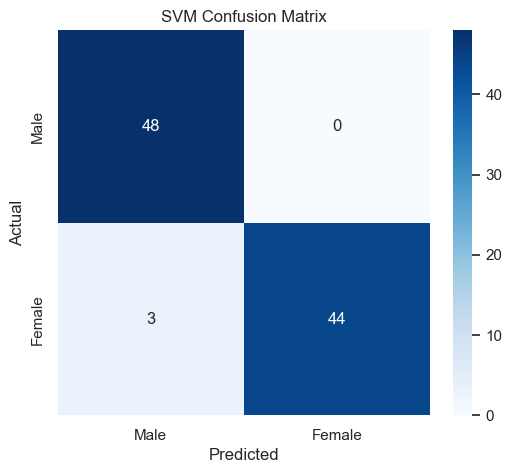

In [120]:
confusion_matrix_plot(y_test, y_pred, "SVM")

# Logistic Regression

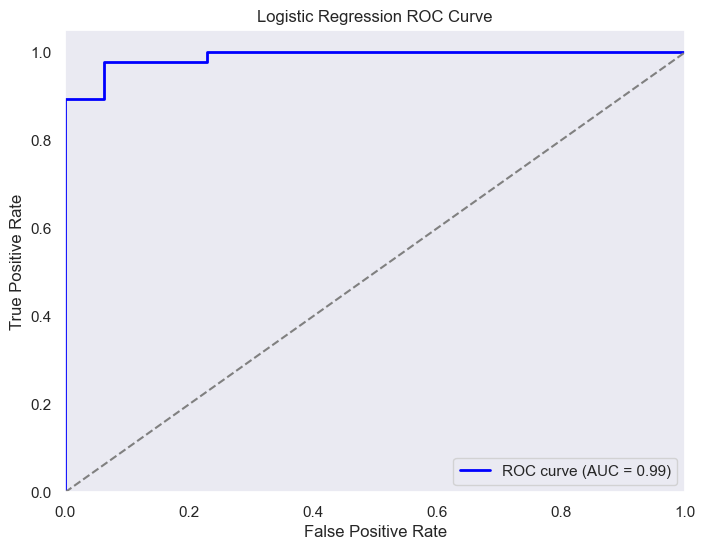

In [122]:
y_pred = predictions["Logistic Regression"]
y_proba = probabilities["Logistic Regression"]

ROC_curve(y_test, y_proba, "Logistic Regression")

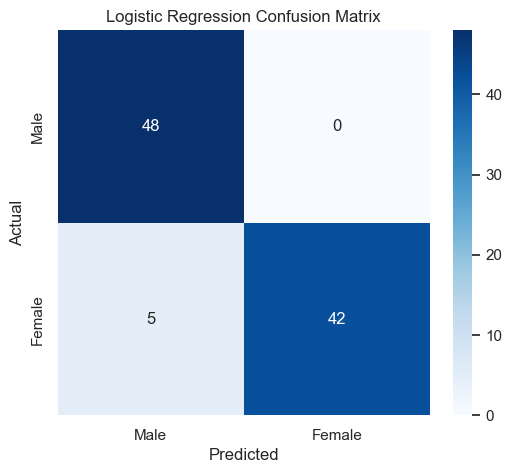

In [123]:
confusion_matrix_plot(y_test, y_pred, "Logistic Regression")    

# KNN

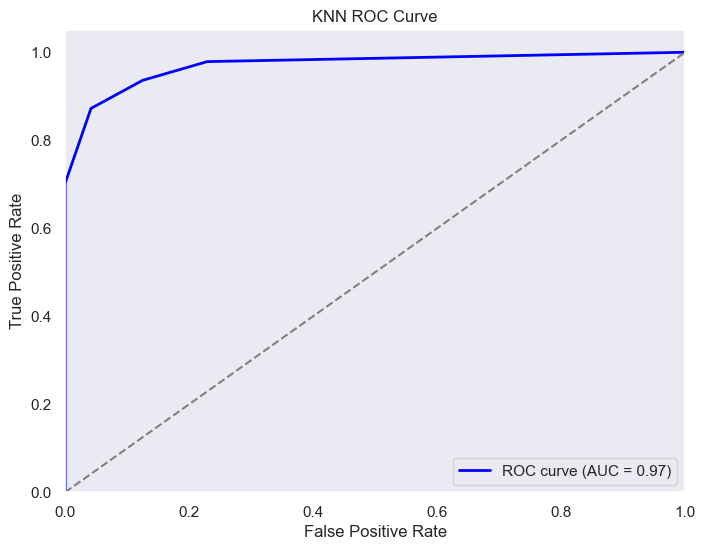

In [124]:
y_pred = predictions["KNN"]
y_proba = probabilities["KNN"]

ROC_curve(y_test, y_proba, "KNN")

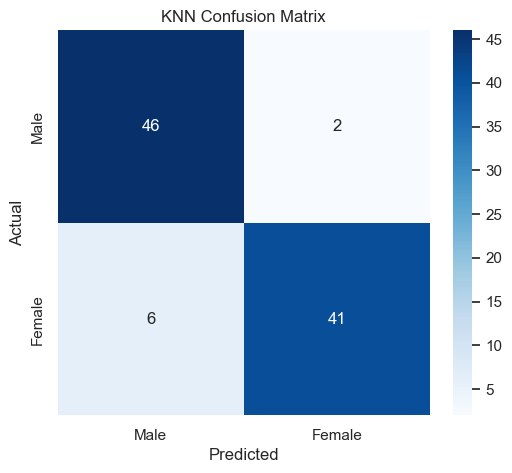

In [125]:
confusion_matrix_plot(y_test, y_pred, "KNN")

# Identity Recognition